# Exploración 1: los pozos que se conectan durante el mes

El pronóstico de agosto de 2026 de la notebook 04 cubre solamente los pozos que ya producían en julio. Los pozos que se conecten **durante** agosto no tienen historia y quedan afuera.

En esta notebook medimos cuánto aportan esos pozos, cómo es la curva de producción de un pozo nuevo y si un pronóstico simple de ese aporte mejora el total.

Definimos como **pozo nuevo** a un pozo en el primer mes en que aparece en la base de producción.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from comun import *

warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.float_format", lambda valor: f"{valor:,.1f}")
plt.rcParams["figure.figsize"] = (11, 4.5)

In [2]:
produccion = cargar_produccion_pais()
resumen = resumen_pozos_nuevos(produccion)

print(f"Registros de producción: {len(produccion):,}")
print(f"Meses: {resumen.index.min():%Y-%m} a {resumen.index.max():%Y-%m}")

Registros de producción: 421,046
Meses: 2006-01 a 2026-07


## 1. Cuántos pozos nuevos aparecen por mes y cuánto producen

Calculamos, para cada mes, la cantidad de pozos que aparecen por primera vez y el petróleo que producen en ese primer mes.

In [3]:
resumen["porcentaje_del_total"] = resumen["petroleo_pozos_nuevos_m3"] / resumen["total_pais_m3"] * 100
resumen["m3_por_pozo_nuevo"] = resumen["petroleo_pozos_nuevos_m3"] / resumen["pozos_nuevos"]

recientes = resumen.loc["2024-01-01":]
display(recientes)

print(f"Promedio desde 2024: {recientes['pozos_nuevos'].mean():.0f} pozos nuevos por mes, "
      f"{recientes['porcentaje_del_total'].mean():.2f} % del petróleo del mes")

,total_pais_m3,pozos_nuevos,petroleo_pozos_nuevos_m3,porcentaje_del_total,m3_por_pozo_nuevo
mes,,,,,
2024-01-01,"1,730,193.7",36.0,"12,329.1",0.7,342.5
2024-02-01,"1,651,045.9",39.0,"25,787.1",1.6,661.2
2024-03-01,"1,802,195.3",44.0,"31,635.9",1.8,719.0
2024-04-01,"1,759,161.2",35.0,"11,370.1",0.6,324.9
2024-05-01,"1,834,969.5",43.0,"11,144.8",0.6,259.2
2024-06-01,"1,810,154.7",30.0,"17,144.7",0.9,571.5
2024-07-01,"1,933,436.6",47.0,"25,579.8",1.3,544.3
2024-08-01,"2,015,479.5",49.0,"20,455.6",1.0,417.5
2024-09-01,"1,867,404.0",33.0,"16,513.9",0.9,500.4


Promedio desde 2024: 41 pozos nuevos por mes, 0.88 % del petróleo del mes


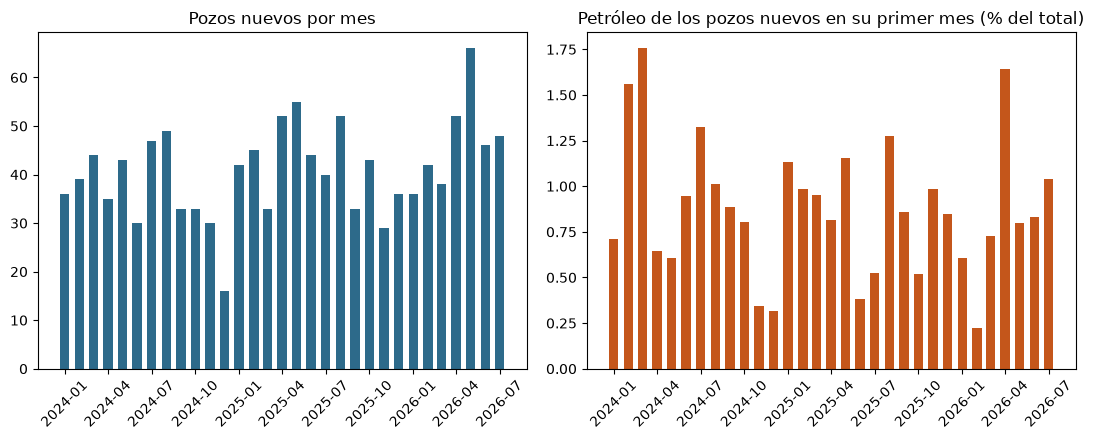

In [4]:
fig, ejes = plt.subplots(1, 2)
ejes[0].bar(recientes.index, recientes["pozos_nuevos"], width=20, color="#2D6A8A")
ejes[0].set_title("Pozos nuevos por mes")
ejes[1].bar(recientes.index, recientes["porcentaje_del_total"], width=20, color="#C4561B")
ejes[1].set_title("Petróleo de los pozos nuevos en su primer mes (% del total)")
for eje in ejes:
    eje.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 2. Curva de vida de un pozo nuevo

El primer mes de un pozo suele ser parcial: se conecta en algún momento del mes. Para entender el aporte de los pozos nuevos en los meses siguientes calculamos la **curva tipo**: la producción media de un pozo nuevo en cada mes de vida.

Usamos los pozos que empezaron en los 24 meses anteriores al corte. Un pozo que no informa producción en uno de sus meses cuenta como cero. Comparamos la curva calculada con datos hasta julio de 2026 y hasta julio de 2025 para ver si cambia con el tiempo.

,Corte julio 2025,Corte julio 2026,cambio_%
mes de vida,,,
1,461.7,502.8,8.9
2,"2,001.3","2,403.7",20.1
3,"3,360.8","4,123.8",22.7
4,"3,391.4","4,150.1",22.4
5,"3,134.3","3,697.4",18.0
6,"2,689.2","3,287.1",22.2
7,"2,337.1","2,904.8",24.3
8,"1,983.0","2,628.4",32.5
9,"1,852.0","2,409.0",30.1


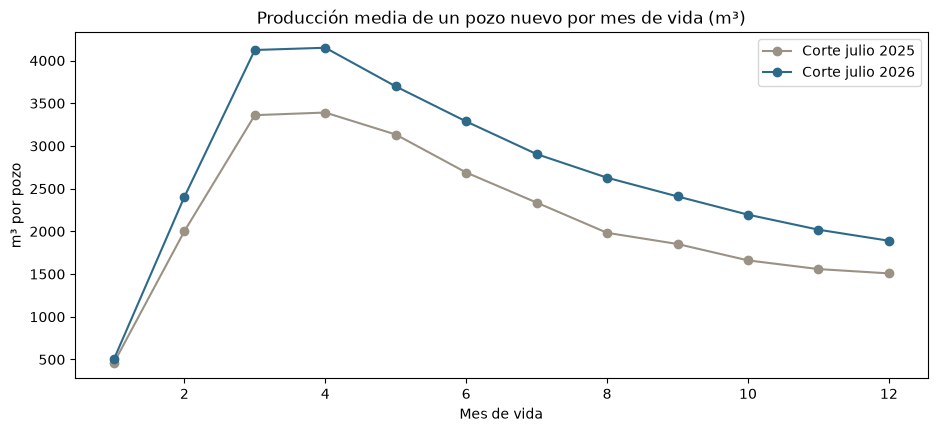

In [5]:
curvas = pd.DataFrame({
    "Corte julio 2025": curva_tipo(produccion, "2025-07-01"),
    "Corte julio 2026": curva_tipo(produccion, "2026-07-01"),
})
curvas.index.name = "mes de vida"
curvas["cambio_%"] = (curvas["Corte julio 2026"] / curvas["Corte julio 2025"] - 1) * 100
display(curvas)

curvas[["Corte julio 2025", "Corte julio 2026"]].plot(marker="o", color=["#9A9284", "#2D6A8A"])
plt.title("Producción media de un pozo nuevo por mes de vida (m³)")
plt.xlabel("Mes de vida")
plt.ylabel("m³ por pozo")
plt.show()

curvas.to_csv(RUTA_RESULTADOS / "curva_tipo_pozo_nuevo.csv")

## 3. Pronóstico del aporte de los pozos nuevos

El aporte de los pozos que se conecten después del mes de corte se estima como:

> pozos que se conectan por mes × producción del pozo según su mes de vida

Para el mes siguiente solo cuenta el primer mes de vida, que es chico. A 3 y 6 meses los pozos nuevos ya están en su pico y su aporte pasa a ser grande, por eso los evaluamos en los tres horizontes que usa la exploración 3.

La sección 2 mostró que cada camada de pozos nuevos produce más que la anterior. Comparamos cuatro variantes:

- **Sin pozos nuevos**: lo que hace hoy el pronóstico de la notebook 04.
- **Simple**: curva tipo de los pozos que empezaron en los últimos 24 meses y cantidad de pozos promedio de los últimos 12 meses.
- **Reciente**: curva de los últimos 12 meses y cantidad de los últimos 6 meses.
- **Reciente + mejora anual**: la variante anterior, corrigiendo la curva por la mejora anual de los pozos nuevos.

Cada mes objetivo entre octubre de 2025 y julio de 2026 se pronostica usando solo información disponible al mes de corte. Como elegimos la variante con estos mismos meses, su error es algo optimista.

In [6]:
variantes = {
    "Sin pozos nuevos": None,
    "Simple (curva 24 m, conteo 12 m)": dict(ventana_curva=24, meses_conteo=12, ajustar_tendencia=False),
    "Reciente (curva 12 m, conteo 6 m)": dict(ventana_curva=12, meses_conteo=6, ajustar_tendencia=False),
    "Reciente + mejora anual": dict(ventana_curva=12, meses_conteo=6, ajustar_tendencia=True),
}

filas = []
for horizonte in (1, 3, 6):
    for mes_objetivo in pd.date_range("2025-10-01", "2026-07-01", freq="MS"):
        mes_corte = mes_objetivo - pd.DateOffset(months=horizonte)
        real = petroleo_conectados_despues(produccion, mes_corte, mes_objetivo)
        total_mes = resumen.loc[mes_objetivo, "total_pais_m3"]
        for nombre, parametros in variantes.items():
            pronostico = 0.0 if parametros is None else pronostico_pozos_nuevos(
                produccion, resumen, mes_corte, horizonte, **parametros
            )[0]
            filas.append({
                "horizonte": horizonte, "mes_objetivo": mes_objetivo, "variante": nombre,
                "real_m3": real, "pronostico_m3": pronostico,
                "peso_en_el_total_%": real / total_mes * 100,
                "error_%": (pronostico / real - 1) * 100,
                "error_sobre_total_%": (pronostico - real) / total_mes * 100,
            })

comparacion_nuevos = pd.DataFrame(filas)
comparacion_nuevos.to_csv(RUTA_RESULTADOS / "backtest_pozos_nuevos.csv", index=False)

resumen_variantes = comparacion_nuevos.groupby(["horizonte", "variante"], sort=False).agg(
    peso_en_el_total=("peso_en_el_total_%", "mean"),
    sesgo=("error_%", "mean"),
    error_absoluto=("error_%", lambda e: e.abs().mean()),
    error_absoluto_sobre_total=("error_sobre_total_%", lambda e: e.abs().mean()),
)
resumen_variantes.columns = [
    "Peso de los pozos nuevos en el total (%)", "Sesgo (%)",
    "Error absoluto medio (%)", "Error absoluto medio sobre el total del país (%)",
]
display(resumen_variantes)

Peso de los pozos nuevos en el total (%)  \
horizonte variante                                                                      
1         Sin pozos nuevos                                                        0.8   
          Simple (curva 24 m, conteo 12 m)                                        0.8   
          Reciente (curva 12 m, conteo 6 m)                                       0.8   
          Reciente + mejora anual                                                 0.8   
3         Sin pozos nuevos                                                       11.3   
          Simple (curva 24 m, conteo 12 m)                                       11.3   
          Reciente (curva 12 m, conteo 6 m)                                      11.3   
          Reciente + mejora anual                                                11.3   
6         Sin pozos nuevos                                                       28.0   
          Simple (curva 24 m, conteo 12 m)                                       28.0   
          Reciente (curva 12 m, conteo 6 m)                                      28.0   
          Reciente + mejora anual                                                28.0   

                                             Sesgo (%)  \
horizonte variante                                       
1         Sin pozos nuevos                      -100.0   
          Simple (curva 24 m, conteo 12 m)         9.5   
          Reciente (curva 12 m, conteo 6 m)        9.4   
          Reciente + mejora anual                 11.5   
3         Sin pozos nuevos                      -100.0   
          Simple (curva 24 m, conteo 12 m)       -20.5   
          Reciente (curva 12 m, conteo 6 m)      -13.0   
          Reciente + mejora anual                 -4.5   
6         Sin pozos nuevos                      -100.0   
          Simple (curva 24 m, conteo 12 m)       -23.8   
          Reciente (curva 12 m, conteo 6 m)      -13.4   
          Reciente + mejora anual                 -5.6   

                                             Error absoluto medio (%)  \
horizonte variante                                                      
1         Sin pozos nuevos                                      100.0   
          Simple (curva 24 m, conteo 12 m)                       48.4   
          Reciente (curva 12 m, conteo 6 m)                      45.7   
          Reciente + mejora anual                                44.0   
3         Sin pozos nuevos                                      100.0   
          Simple (curva 24 m, conteo 12 m)                       22.0   
          Reciente (curva 12 m, conteo 6 m)                      16.5   
          Reciente + mejora anual                                14.1   
6         Sin pozos nuevos                                      100.0   
          Simple (curva 24 m, conteo 12 m)                       23.8   
          Reciente (curva 12 m, conteo 6 m)                      15.1   
          Reciente + mejora anual                                11.7   

                                             Error absoluto medio sobre el total del país (%)  
horizonte variante                                                                             
1         Sin pozos nuevos                                                                0.8  
          Simple (curva 24 m, conteo 12 m)                                                0.3  
          Reciente (curva 12 m, conteo 6 m)                                               0.3  
          Reciente + mejora anual                                                         0.3  
3         Sin pozos nuevos                                                               11.3  
          Simple (curva 24 m, conteo 12 m)                                                2.7  
          Reciente (curva 12 m, conteo 6 m)                                               2.0  
          Reciente + mejora anual                                                         1.6  
6 

## 4. Agosto de 2026 con los pozos nuevos

Sumamos al pronóstico de la notebook 04 (pozos que ya producían en julio, modelo de 24 meses) el aporte esperado de los pozos que se conecten en agosto, con el promedio de 12 meses.

In [7]:
predicciones = pd.read_csv(RUTA_DATOS / "predicciones_produccion_agosto_2026.csv")
existentes_agosto = predicciones["produccion_predicha_m3"].sum()
nuevos_agosto, pozos_por_mes = pronostico_pozos_nuevos(produccion, resumen, "2026-07-01", horizonte=1)
total_julio = resumen.loc["2026-07-01", "total_pais_m3"]

agosto = pd.DataFrame({
    "m³": [total_julio, existentes_agosto, nuevos_agosto, existentes_agosto + nuevos_agosto],
}, index=["Julio 2026 (real, todos los pozos)", "Agosto: pozos que ya producían",
          "Agosto: pozos que se conecten", "Agosto: total"])
agosto["vs julio %"] = (agosto["m³"] / total_julio - 1) * 100
# Para las dos partes del pronóstico mostramos cuántos puntos suma cada una.
agosto.loc[agosto.index[0], "vs julio %"] = np.nan
agosto.loc[agosto.index[2], "vs julio %"] = agosto.loc[agosto.index[2], "m³"] / total_julio * 100
agosto = agosto.rename(columns={"vs julio %": "vs julio % (puntos para pozos nuevos)"})
display(agosto)
print(f"Pozos que se espera conectar en agosto: {pozos_por_mes:.0f}")

agosto.to_csv(RUTA_RESULTADOS / "agosto_con_pozos_nuevos.csv")

,m³,vs julio % (puntos para pozos nuevos)
"Julio 2026 (real, todos los pozos)","3,198,190.3",NaN
Agosto: pozos que ya producían,"3,235,485.8",1.2
Agosto: pozos que se conecten,"32,726.0",1.0
Agosto: total,"3,268,211.8",2.2


Pozos que se espera conectar en agosto: 49


## Conclusiones

- **El mes siguiente casi no cambia.** Se conectan unos 40 a 50 pozos por mes, pero en su primer mes producen poco (unos 500 m³ cada uno, porque se conectan a mitad de mes). Representan menos del 1 % del petróleo del mes.
- **A 3 y 6 meses los pozos nuevos son decisivos.** Un pozo nuevo llega a su pico en el tercer y cuarto mes de vida, con unos 4.100 m³, ocho veces su primer mes. Los pozos conectados después del corte explican en promedio el 11 % del total a 3 meses y el 28 % a 6 meses.
- **Cada camada produce más que la anterior.** La curva de los pozos que empezaron hasta julio de 2026 es entre 20 % y 30 % más alta que la de un año antes. Por eso el método simple, que promedia 24 meses de pozos, subestima el aporte de los nuevos en 20 a 24 %.
- **La variante elegida** (curva de los últimos 12 meses, cantidad de pozos de los últimos 6 meses y corrección por la mejora anual) reduce el sesgo a −5 % y el error sobre el total del país de 6,9 % a 3,4 % a 6 meses. Como se eligió con los mismos meses en que se evalúa, este resultado es algo optimista.
- **Agosto de 2026**: a los 3,24 millones de m³ de los pozos que ya producían se suman unos 33 mil m³ de los aproximadamente 49 pozos que se conecten. El total pasa de +1,2 % a **+2,2 %** respecto de julio.